# A Proximity-Based Early Warning System for Gentrification in California
**UE24CS352A – Machine Learning · Mini-Project**

| | |
|---|---|
| **Problem** | Predict whether a California Census tract's housing cost rises over 2012–2016 (`housing_gentrification_label`) using only information available *before* 2012 |
| **Data** | U.S. Census ACS 5-year tract data (2010, 2011, 2012, 2016); one row per tract |
| **Features** | 150 census-variable changes (2010→2011), the tract's own pre-2012 change, and *proximity* features (spatial lag, local Moran's I) built from neighbouring tracts |
| **Task type** | Binary classification (+ a regression variant on the cost change) |
| **Evaluation** | Repeated stratified cross-validation on train+validation; test set used **once** |
| **Reference** | Pattabi, *A Proximity-Based Early Warning System for Gentrification in California*, Stanford CS229 (2018) |

**Notebook map**
1 Setup · 2 Data & validation · 3 Exploration · 4 Features · 5 Algorithms · 6 Feature-set comparison · 7 Tuning · 8 Label-noise filtering · 9 Proximity ablation · 10 Noise ceiling · 11 Final test · 12 Feature importance · 13 Demo · 14 Summary · 15 Limitations

Every number is computed by this notebook; nothing is typed in by hand.

## 1. Setup and configuration

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import rankdata
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)

# ---------------- configuration ----------------
DATA_PATH   = os.environ.get("DATA_PATH", "../data/final_dataset.csv")
QUICK       = os.environ.get("QUICK", "0") == "1"   # True = fast pass (fewer repeats/trees)
SEED        = 42
N_REPEATS   = 1 if QUICK else 2      # cross-validation repeats
N_TREES     = 150 if QUICK else 300  # Random Forest trees
N_TUNE_ITER = 6 if QUICK else 20     # XGBoost random-search iterations

TARGET, RESPONSE = "housing_gentrification_label", "housing_cost_response"
SPATIAL = ["spatial_lag_housing_pre2012", "local_morans_I_housing_pre2012",
           "spatial_lag_income_pre2012", "local_morans_I_income_pre2012"]
PRE = ["pre_housing_change", "pre_income_change"]

# human-readable algorithm names used in every table and figure
ALGO = {"logreg_L1": "Logistic Regression (L1)", "rf": "Random Forest",
        "xgb": "XGBoost Classifier", "xgb_reg": "XGBoost Regressor",
        "ensemble": "Rank-Averaged Ensemble"}

## 2. Data loading and validation
The dataset was assembled from the Census ACS geodatabases. During validation, the 150 `delta_2010_2011_*` columns of the original build were found to be attached to the wrong tracts; they were **rebuilt from the raw 2010 and 2011 files, joined on `tract_id`** (`fix_dataset.py`). The target, label, spatial features and pre-2012 changes were checked against the raw Census files and are correct. The checks below confirm the loaded file is consistent.

In [2]:
df = pd.read_csv(r"C:\Users\User\OneDrive\Documents\SEM 5\ML_mini_pro\data\final_dataset.csv")
print("Shape:", df.shape)
print("\nSplit sizes:\n", df["split"].value_counts().to_string())

# --- ID consistency: tract_id must agree with county_fips / tract_code ---
id_county = float(((df["tract_id"] // 1_000_000) % 1000 == df["county_fips"]).mean())
id_tract = float((df["tract_id"] % 1_000_000 == df["tract_code"]).mean())
print(f"\ntract_id agrees with county_fips: {id_county:.1%} | with tract_code: {id_tract:.1%}")
if min(id_county, id_tract) < 0.99:
    print("WARNING: ID columns disagree - the file may be mis-merged. Rebuild it with fix_dataset.py.")

# --- label definition and missing values ---
label_rule = float(((df[RESPONSE] > 0).astype(int) == df[TARGET]).mean())
miss = df.isna().sum()[lambda s: s > 0].sort_values(ascending=False)
print(f"\nLabel == (cost change > 0): {label_rule:.1%} agreement")
print(f"Columns with missing values: {len(miss)} (total missing cells: {int(miss.sum())})")
print("Most affected columns:\n", miss.head(5).to_string())

Shape: (7965, 167)

Split sizes:
 split
train         7168
test           399
validation     398

tract_id agrees with county_fips: 100.0% | with tract_code: 100.0%

Label == (cost change > 0): 100.0% agreement
Columns with missing values: 155 (total missing cells: 27179)
Most affected columns:
 delta_2010_2011_DP4_HC01_VC143_Y    7690
delta_2010_2011_DP4_HC01_VC185_Y    7432
delta_2010_2011_DP3_HC01_VC36       7188
delta_2010_2011_DP4_HC01_VC07       3296
local_morans_I_housing_pre2012       557


## 3. Exploratory view of the target

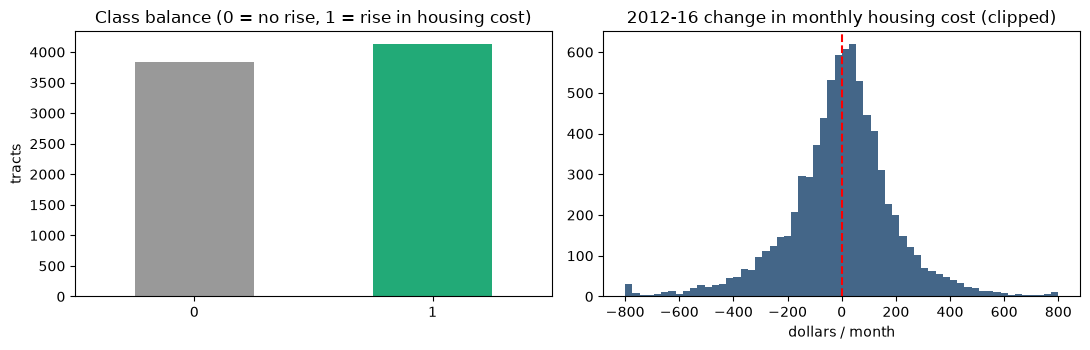

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df[TARGET].value_counts().sort_index().plot.bar(ax=ax[0], color=["#999", "#2a7"], rot=0)
ax[0].set(title="Class balance (0 = no rise, 1 = rise in housing cost)", xlabel="", ylabel="tracts")
ax[1].hist(df[RESPONSE].clip(-800, 800), bins=60, color="#468")
ax[1].axvline(0, color="r", ls="--")
ax[1].set(title="2012-16 change in monthly housing cost (clipped)", xlabel="dollars / month")
plt.tight_layout(); plt.show()

The label is the **sign of a noisy cost change**, so tracts near zero change are close to coin flips. This limits achievable accuracy for any model and is quantified in section 10.

## 4. Feature engineering
No leakage: only 2010→2011 and pre-2012 quantities are used. IDs, `split`, and everything derived from the 2012–2016 outcome are excluded.

| Feature group | Description |
|---|---|
| **Census deltas (150)** | 2010→2011 change in ACS profile variables (households, education, income, housing, ...) |
| **Proximity features (4)** | Spatial lag and local Moran's I of the pre-2012 housing-cost and income change, from Queen-contiguity neighbours |
| **Own pre-2012 change (2 + 2 flags)** | The tract's own 2010→2011 housing-cost and income change, with missing-value flags (NaNs are median-imputed) |
| **Neighbour contrasts (2)** | Own pre-2012 change minus the neighbours' average change (housing and income) |

Four feature sets of increasing richness are compared:

In [4]:
delta_cols = [c for c in df.columns if c.startswith("delta_")]
X_all = df[delta_cols + SPATIAL + PRE].copy()
X_all["pre_housing_missing"] = df["pre_housing_change"].isna().astype(int)
X_all["pre_income_missing"] = df["pre_income_change"].isna().astype(int)
X_all["housing_vs_neighbors"] = df["pre_housing_change"] - df["spatial_lag_housing_pre2012"]
X_all["income_vs_neighbors"] = df["pre_income_change"] - df["spatial_lag_income_pre2012"]

PRE_F = PRE + ["pre_housing_missing", "pre_income_missing"]
ENG = ["housing_vs_neighbors", "income_vs_neighbors"]
FEATURE_SETS = {
    "A_baseline (census deltas + proximity)": delta_cols + SPATIAL,
    "B  + own pre-2012 change":               delta_cols + SPATIAL + PRE_F,
    "C  + neighbour contrasts":               delta_cols + SPATIAL + PRE_F + ENG,
    "D_core (no census deltas)":              SPATIAL + PRE_F + ENG,
}
fs_sizes = pd.Series({k: len(v) for k, v in FEATURE_SETS.items()}, name="n_features")
display(fs_sizes.to_frame())

dev = df["split"].isin(["train", "validation"]).values
test = (df["split"] == "test").values
X_dev, y_dev, r_dev = X_all[dev].reset_index(drop=True), df.loc[dev, TARGET].values, df.loc[dev, RESPONSE].values
X_te, y_te = X_all[test].reset_index(drop=True), df.loc[test, TARGET].values
print(f"Development rows (train+validation): {len(y_dev)} | Test rows: {len(y_te)}")
print(f"Majority-class accuracy -> dev {max(y_dev.mean(), 1-y_dev.mean()):.4f} | test {max(y_te.mean(), 1-y_te.mean()):.4f}")

,n_features
A_baseline (census deltas + proximity),154
B + own pre-2012 change,158
C + neighbour contrasts,160
D_core (no census deltas),10


Development rows (train+validation): 7566 | Test rows: 399
Majority-class accuracy -> dev 0.5188 | test 0.5188


## 5. Algorithms used
Five scoring models are compared, plus supporting methods. Strong regularisation matters here: ~150 noisy features and ~7.5k rows.

| Label | Algorithm | Family | Predicts | Key regularisation / settings | Role |
|---|---|---|---|---|---|
| `logreg_L1` | **Logistic Regression (L1)** | Linear | P(rise) | L1 penalty (`C` tuned); quantile-transformed inputs | Linear baseline, built-in feature selection |
| `rf` | **Random Forest** | Bagged decision trees | P(rise) | 300 trees, `max_features=18`, `min_samples_leaf=15` | Non-linear baseline |
| `xgb` | **XGBoost Classifier** | Gradient-boosted trees | P(rise) | shallow trees, L2 `reg_lambda`, subsampling (randomised search) | Main boosted model |
| `xgb_reg` | **XGBoost Regressor** | Gradient-boosted trees | cost change ($), used as the score | same settings; target winsorised at 1st/99th percentile | Uses the *size* of the change, not only its sign |
| `ensemble` | **Rank-Averaged Ensemble** | Model averaging | combined score | average of the other models' rank-normalised scores | Variance reduction |

**Supporting methods:** median imputation · quantile transform (logistic regression only) · repeated stratified 5-fold cross-validation · randomized search (XGBoost) and grid search (`C`) · training-label noise filtering · paired ablation · bootstrap confidence intervals · XGBoost gain importance.

**Scoring and labelling.** Models are compared by **ROC-AUC**. For accuracy / precision / recall each model labels the top *p*% of scores as positive, where *p* is the training positive rate; this avoids over-predicting the positive class. As a consequence, the number of predicted positives equals the number of actual positives, so **precision and recall come out (almost) equal by construction**.

In [5]:
PARAMS = {"C": 0.02,
          "xgb": dict(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
                      colsample_bytree=0.4, min_child_weight=10, reg_lambda=25)}   # overwritten by tuning (section 7)

def _imp(): return SimpleImputer(strategy="median")

def make_classifiers(n_feat, seed):
    """Logistic Regression (L1), Random Forest, XGBoost Classifier."""
    mf = 18 if n_feat >= 60 else max(2, n_feat // 2)
    return {
        "logreg_L1": Pipeline([("imp", _imp()),
                               ("qt", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=seed)),
                               ("m", LogisticRegression(penalty="l1", solver="liblinear", C=PARAMS["C"], max_iter=500))]),
        "rf": Pipeline([("imp", _imp()),
                        ("m", RandomForestClassifier(n_estimators=N_TREES, max_features=mf, min_samples_leaf=15,
                                                     n_jobs=-1, random_state=seed))]),
        "xgb": Pipeline([("imp", _imp()),
                         ("m", XGBClassifier(**PARAMS["xgb"], tree_method="hist", n_jobs=-1,
                                             random_state=seed, eval_metric="logloss"))]),
    }

def make_regressor(seed):
    """XGBoost Regressor on the (winsorised) housing-cost change."""
    return Pipeline([("imp", _imp()),
                     ("m", XGBRegressor(**PARAMS["xgb"], tree_method="hist", n_jobs=-1, random_state=seed))])

def fit_scores(Xtr, ytr, rtr, Xva, seed, return_models=False):
    """Fit all five models on the training rows; return one score vector per model for Xva."""
    s, fitted = {}, {}
    for name, mdl in make_classifiers(Xtr.shape[1], seed).items():
        mdl.fit(Xtr, ytr); s[name] = mdl.predict_proba(Xva)[:, 1]; fitted[name] = mdl
    lo, hi = np.percentile(rtr, [1, 99])
    reg = make_regressor(seed).fit(Xtr, np.clip(rtr, lo, hi))
    s["xgb_reg"], fitted["xgb_reg"] = reg.predict(Xva), reg
    s["ensemble"] = np.mean([rankdata(v) / len(v) for v in s.values()], axis=0)
    return (s, fitted) if return_models else s

def to_labels(score, pos_rate):
    """Label the top pos_rate share of scores as positive."""
    return (score >= np.quantile(score, 1 - pos_rate)).astype(int)

## 6. Cross-validated comparison of feature sets (all five algorithms)

In [6]:
def cv_eval(cols, drop_below=0, n_splits=5, seed=SEED):
    """Repeated stratified CV on train+val. Rows with |cost change| < drop_below are removed from
    TRAINING folds only; evaluation always uses every row of the held-out fold."""
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=N_REPEATS, random_state=seed)
    rows, oof = [], {}
    for i, (tr, va) in enumerate(rskf.split(X_dev, y_dev)):
        if drop_below > 0:
            tr = tr[np.abs(r_dev[tr]) >= drop_below]
        sc = fit_scores(X_dev.iloc[tr][cols], y_dev[tr], r_dev[tr], X_dev.iloc[va][cols], seed + i)
        for name, s in sc.items():
            pred = to_labels(s, y_dev[tr].mean())
            rows.append(dict(fold=i, model=name, auc=roc_auc_score(y_dev[va], s),
                             acc=accuracy_score(y_dev[va], pred)))
            oof.setdefault(name, np.full((N_REPEATS, len(y_dev)), np.nan))[i // n_splits, va] = s
    return pd.DataFrame(rows), oof

def summarise(res):
    g = res.groupby("model")
    return pd.DataFrame({"AUC": g.auc.mean(), "AUC_sd": g.auc.std(),
                         "Acc": g.acc.mean(), "Acc_sd": g.acc.std()}).sort_values("AUC", ascending=False).round(4)

def with_algo(summ, **meta):
    d = summ.reset_index().rename(columns={"model": "key"})
    d.insert(0, "algorithm", d["key"].map(ALGO))
    for k, v in meta.items(): d.insert(0, k, v)
    return d

exp1, summ1, long1 = {}, {}, []
for name, cols in FEATURE_SETS.items():
    exp1[name], _ = cv_eval(cols)
    summ1[name] = summarise(exp1[name])
    long1.append(with_algo(summ1[name], feature_set=name))
    print(f"\n{name}"); display(summ1[name].rename(index=ALGO))

cv_featureset_table = pd.concat(long1, ignore_index=True)
fs_table = pd.DataFrame({k: v["AUC"] for k, v in summ1.items()}).T
display(Markdown("**Mean CV ROC-AUC by feature set and algorithm**")); display(fs_table.rename(columns=ALGO).round(4))
best_fs = fs_table.max(axis=1).idxmax()
print("Best feature set by CV AUC:", best_fs)


A_baseline (census deltas + proximity)


,AUC,AUC_sd,Acc,Acc_sd
model,,,,
XGBoost Regressor,0.7002,0.0124,0.6423,0.0146
Random Forest,0.6981,0.0094,0.6463,0.0109
XGBoost Classifier,0.6978,0.0072,0.6465,0.0102
Rank-Averaged Ensemble,0.6958,0.0105,0.6413,0.0135
Logistic Regression (L1),0.5801,0.0136,0.5572,0.0140



B  + own pre-2012 change


,AUC,AUC_sd,Acc,Acc_sd
model,,,,
XGBoost Regressor,0.7017,0.0131,0.6445,0.0154
XGBoost Classifier,0.7001,0.0079,0.6482,0.0102
Random Forest,0.7001,0.0095,0.6468,0.0084
Rank-Averaged Ensemble,0.6978,0.0112,0.6427,0.0135
Logistic Regression (L1),0.5803,0.0141,0.5568,0.0156



C  + neighbour contrasts


,AUC,AUC_sd,Acc,Acc_sd
model,,,,
Random Forest,0.7023,0.0093,0.6470,0.0106
XGBoost Regressor,0.7017,0.0133,0.6483,0.0148
XGBoost Classifier,0.7010,0.0079,0.6464,0.0108
Rank-Averaged Ensemble,0.6983,0.0113,0.6449,0.0122
Logistic Regression (L1),0.5805,0.0139,0.5571,0.0153



D_core (no census deltas)


,AUC,AUC_sd,Acc,Acc_sd
model,,,,
XGBoost Classifier,0.5874,0.0113,0.5611,0.0132
XGBoost Regressor,0.5867,0.0123,0.5625,0.0077
Rank-Averaged Ensemble,0.5855,0.0104,0.5604,0.0139
Random Forest,0.5747,0.0084,0.5463,0.0065
Logistic Regression (L1),0.5499,0.0120,0.5326,0.0100


**Mean CV ROC-AUC by feature set and algorithm**

model,Rank-Averaged Ensemble,Logistic Regression (L1),Random Forest,XGBoost Classifier,XGBoost Regressor
A_baseline (census deltas + proximity),0.6958,0.5801,0.6981,0.6978,0.7002
B + own pre-2012 change,0.6978,0.5803,0.7001,0.7001,0.7017
C + neighbour contrasts,0.6983,0.5805,0.7023,0.7010,0.7017
D_core (no census deltas),0.5855,0.5499,0.5747,0.5874,0.5867


Best feature set by CV AUC: C  + neighbour contrasts


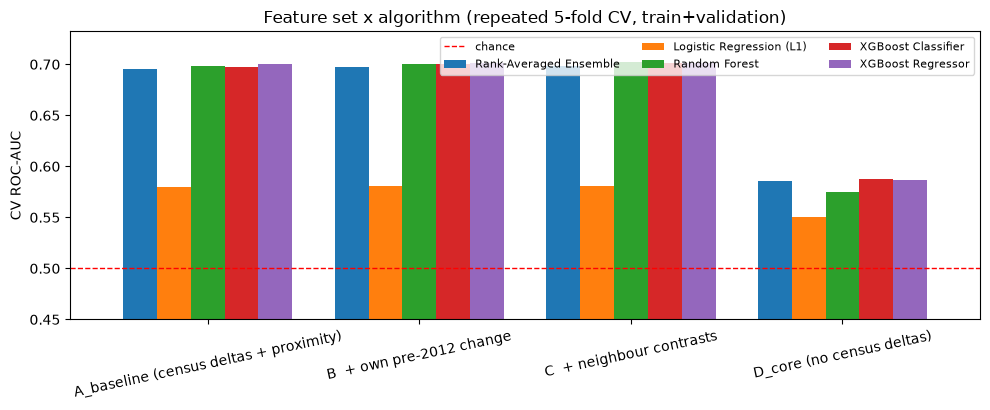

In [7]:
ax = fs_table.rename(columns=ALGO).plot.bar(figsize=(10, 4.2), rot=12, width=0.8)
ax.axhline(0.5, color="r", ls="--", lw=1, label="chance")
ax.set(ylabel="CV ROC-AUC", title="Feature set x algorithm (repeated 5-fold CV, train+validation)")
ax.set_ylim(0.45, max(0.7, fs_table.values.max() + 0.03)); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

## 7. Hyper-parameter tuning
Tuning uses cross-validation on the training data only.
- **Logistic Regression (L1):** grid search over the regularisation strength `C`.
- **XGBoost:** randomized search over shallow-tree, strongly regularised settings (depth, learning rate, `reg_lambda`, `min_child_weight`, subsampling). The tuned values are shared by the XGBoost Classifier and Regressor.
- **Random Forest:** fixed, regularised settings (`max_features=18`, `min_samples_leaf=15`).

In [8]:
cols_best = FEATURE_SETS[best_fs]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)

# --- Logistic Regression (L1): choose C ---
c_scores = {}
for Cval in [0.005, 0.01, 0.02, 0.05, 0.1, 0.3]:
    PARAMS["C"] = Cval
    m = make_classifiers(len(cols_best), SEED)["logreg_L1"]
    c_scores[Cval] = cross_val_score(m, X_dev[cols_best], y_dev, cv=skf, scoring="roc_auc").mean()
PARAMS["C"] = max(c_scores, key=c_scores.get)
print("L1 C scores:", {k: round(float(v), 4) for k, v in c_scores.items()}, "-> C =", PARAMS["C"])

# --- XGBoost: randomized search ---
space = {"m__n_estimators": [150, 250, 400], "m__max_depth": [2, 3, 4],
         "m__learning_rate": [0.02, 0.03, 0.05, 0.08], "m__subsample": [0.6, 0.8, 1.0],
         "m__colsample_bytree": [0.2, 0.4, 0.6], "m__min_child_weight": [5, 10, 20, 40],
         "m__reg_lambda": [10, 25, 50, 100]}
xgb_pipe = Pipeline([("imp", _imp()), ("m", XGBClassifier(tree_method="hist", n_jobs=-1,
                                                        random_state=SEED, eval_metric="logloss"))])
search = RandomizedSearchCV(xgb_pipe, space, n_iter=N_TUNE_ITER, scoring="roc_auc", cv=skf,
                            random_state=SEED, n_jobs=1).fit(X_dev[cols_best], y_dev)
PARAMS["xgb"] = {k.replace("m__", ""): v for k, v in search.best_params_.items()}
srch = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
srch = srch[[c for c in srch.columns if c.startswith("param_") or c in ("mean_test_score", "std_test_score", "rank_test_score")]]
print("XGBoost best params:", PARAMS["xgb"], "| search CV AUC: %.4f" % search.best_score_)

L1 C scores: {0.005: 0.5383, 0.01: 0.5702, 0.02: 0.5796, 0.05: 0.5784, 0.1: 0.5755, 0.3: 0.5725} -> C = 0.02
XGBoost best params: {'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 250, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.2} | search CV AUC: 0.7038


## 8. Label-noise filtering
Tracts whose cost change is close to zero have essentially random labels. We test removing them from the **training folds only** (never from evaluation), at several thresholds on |cost change| (dollars/month; 0 = keep everything). The best configuration is selected by CV AUC.

In [9]:
exp2, oof2, rows = {}, {}, []
for thr in [0, 25, 50, 100]:
    exp2[thr], oof2[thr] = cv_eval(cols_best, drop_below=thr)
    rows.append(with_algo(summarise(exp2[thr]), drop_below=thr, feature_set=best_fs))
tune_table = pd.concat(rows, ignore_index=True)
piv = tune_table.pivot(index="drop_below", columns="algorithm", values="AUC")
display(Markdown(f"**Mean CV ROC-AUC with tuned models on `{best_fs}`** (rows = minimum |cost change| kept in training)"))
display(piv.round(4))

best = tune_table.sort_values("AUC", ascending=False).iloc[0]
BEST_THR, BEST_MODEL = int(best.drop_below), best.key
print(f"Selected by CV -> {ALGO[BEST_MODEL]} | training filter: |change| >= {BEST_THR} | CV AUC {best.AUC:.4f}")

**Mean CV ROC-AUC with tuned models on `C  + neighbour contrasts`** (rows = minimum |cost change| kept in training)

algorithm,Logistic Regression (L1),Random Forest,Rank-Averaged Ensemble,XGBoost Classifier,XGBoost Regressor
drop_below,,,,,
0,0.5805,0.7023,0.7006,0.7026,0.7056
25,0.5795,0.7009,0.7002,0.7037,0.7051
50,0.5774,0.7003,0.6993,0.7042,0.7042
100,0.5747,0.7008,0.6988,0.7037,0.7038


Selected by CV -> XGBoost Regressor | training filter: |change| >= 0 | CV AUC 0.7056


## 9. Ablation: do the proximity features help? (paired, identical folds)

In [10]:
prox_like = set(SPATIAL + ENG)
cols_wo = [c for c in cols_best if c not in prox_like]
res_wo, _ = cv_eval(cols_wo, drop_below=BEST_THR)
a = exp2[BEST_THR].query("model == @BEST_MODEL").sort_values("fold").auc.values
b = res_wo.query("model == @BEST_MODEL").sort_values("fold").auc.values
diff = a - b
abl_mean, abl_se = float(diff.mean()), float(diff.std(ddof=1) / np.sqrt(len(diff)))
abl_tbl = pd.DataFrame({"with proximity features": [a.mean()], "without proximity features": [b.mean()],
                        "paired difference": [abl_mean], "std. error": [abl_se]}, index=[ALGO[BEST_MODEL]])
display(abl_tbl.round(4))
abl_sig = abl_mean > 2 * abl_se
print("Difference larger than 2 standard errors:", abl_sig, "(CV folds overlap, so the SE is optimistic)")

,with proximity features,without proximity features,paired difference,std. error
XGBoost Regressor,0.7056,0.7024,0.0031,0.0013


Difference larger than 2 standard errors: True (CV folds overlap, so the SE is optimistic)


## 10. How much of the error is label noise?

,AUC,n
size of |cost change|,,
smallest 25%,0.5455,1892.0
25-50%,0.6673,1911.0
50-75%,0.7547,1879.0
largest 25%,0.8356,1884.0


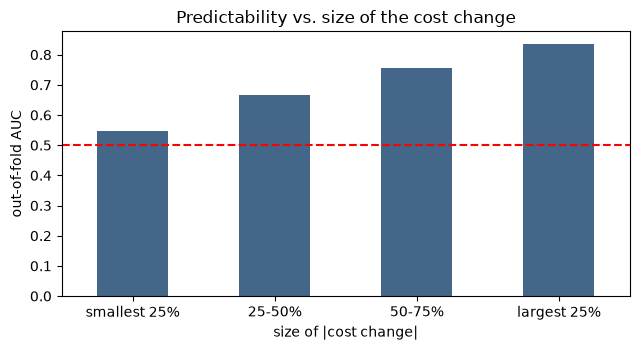

In [11]:
p_oof = np.nanmean(oof2[BEST_THR][BEST_MODEL], axis=0)
mag = np.abs(r_dev)
bins = pd.qcut(mag, 4, labels=["smallest 25%", "25-50%", "50-75%", "largest 25%"])
noise_tbl = pd.DataFrame({b_: {"AUC": roc_auc_score(y_dev[bins == b_], p_oof[bins == b_]),
                               "n": int((bins == b_).sum())} for b_ in bins.categories}).T
noise_tbl.index.name = "size of |cost change|"
display(noise_tbl.round(4))
ax = noise_tbl["AUC"].plot.bar(rot=0, figsize=(6.5, 3.6), color="#468")
ax.axhline(0.5, color="r", ls="--"); ax.set(ylabel="out-of-fold AUC", title="Predictability vs. size of the cost change")
plt.tight_layout(); plt.show()

If AUC rises with the size of the change, the limited overall score is mainly a **label-noise ceiling** (small changes are unpredictable), not a pipeline error.

## 11. Final evaluation on the untouched test set
Everything above used train+validation only. The configuration chosen by CV is refit on **all** development rows and evaluated on the test set **once**, with bootstrap 95% confidence intervals. All five algorithms are shown for the write-up table, but the selection was made by CV, not by this table.

In [12]:
keep = np.abs(r_dev) >= BEST_THR if BEST_THR > 0 else np.ones(len(y_dev), bool)
sc_te, fitted_models = fit_scores(X_dev.loc[keep, cols_best], y_dev[keep], r_dev[keep],
                                  X_te[cols_best], SEED, return_models=True)
pos_rate = float(y_dev[keep].mean())

def boot_ci(y, s, n=1000, seed=0):
    rng, A, K = np.random.default_rng(seed), [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        A.append(roc_auc_score(y[i], s[i])); K.append(accuracy_score(y[i], to_labels(s[i], pos_rate)))
    return np.percentile(A, [2.5, 97.5]), np.percentile(K, [2.5, 97.5])

rows = []
for name, s in sc_te.items():
    pred = to_labels(s, pos_rate)
    ac, kc = boot_ci(y_te, s)
    rows.append({"algorithm": ALGO[name], "key": name, "AUC": roc_auc_score(y_te, s), "AUC_ci_low": ac[0], "AUC_ci_high": ac[1],
                 "Accuracy": accuracy_score(y_te, pred), "Acc_ci_low": kc[0], "Acc_ci_high": kc[1],
                 "Precision": precision_score(y_te, pred), "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred)})
test_table = pd.DataFrame(rows).set_index("algorithm").round(4)
display(test_table.drop(columns="key"))

s_fin = sc_te[BEST_MODEL]; pred_fin = to_labels(s_fin, pos_rate)
auc_te, acc_te = roc_auc_score(y_te, s_fin), accuracy_score(y_te, pred_fin)
auc_ci, acc_ci = boot_ci(y_te, s_fin)
base_acc = float(max(y_te.mean(), 1 - y_te.mean()))
print(f"SELECTED: {ALGO[BEST_MODEL]}  ({best_fs}, training filter >= {BEST_THR})")
print(f"Test ROC-AUC  {auc_te:.4f}   95% CI [{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]")
print(f"Test accuracy {acc_te:.4f}   95% CI [{acc_ci[0]:.3f}, {acc_ci[1]:.3f}]   (majority baseline {base_acc:.4f})")

# per-tract test predictions (used by the demo cell below)
pred_df = pd.DataFrame({"tract_id": df.loc[test, "tract_id"].values, "county_fips": df.loc[test, "county_fips"].values,
                        "actual_label": y_te, "actual_cost_change": df.loc[test, RESPONSE].values})
for name, s in sc_te.items():
    pred_df[f"score_{name}"] = s
pred_df["predicted_label_selected"] = pred_fin

,AUC,AUC_ci_low,AUC_ci_high,Accuracy,Acc_ci_low,Acc_ci_high,Precision,Recall,F1
algorithm,,,,,,,,,
Logistic Regression (L1),0.5921,0.5390,0.6466,0.5338,0.4937,0.5915,0.5507,0.5507,0.5507
Random Forest,0.7081,0.6575,0.7562,0.6441,0.5989,0.6967,0.6570,0.6570,0.6570
XGBoost Classifier,0.7073,0.6533,0.7551,0.6491,0.6065,0.6992,0.6618,0.6618,0.6618
XGBoost Regressor,0.7082,0.6606,0.7538,0.6391,0.5940,0.6917,0.6522,0.6522,0.6522
Rank-Averaged Ensemble,0.7037,0.6518,0.7503,0.6391,0.5915,0.6892,0.6522,0.6522,0.6522


SELECTED: XGBoost Regressor  (C  + neighbour contrasts, training filter >= 0)
Test ROC-AUC  0.7082   95% CI [0.661, 0.754]
Test accuracy 0.6391   95% CI [0.594, 0.692]   (majority baseline 0.5188)


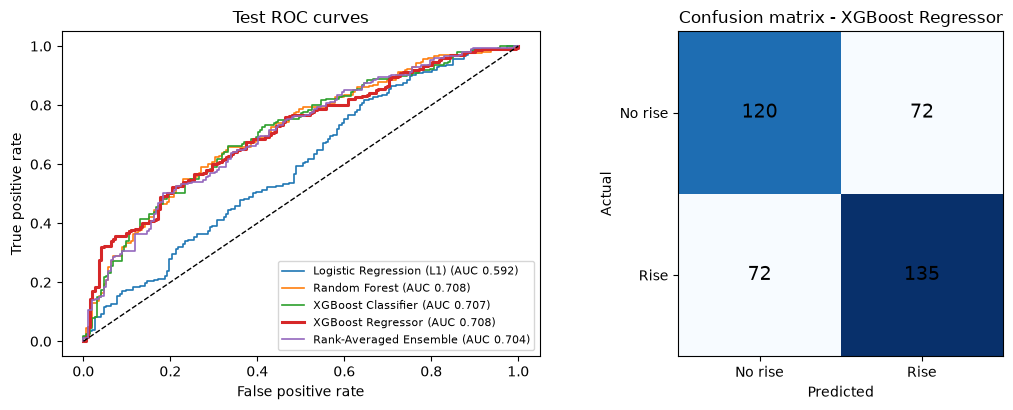

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for name, s in sc_te.items():
    fpr, tpr, _ = roc_curve(y_te, s)
    ax[0].plot(fpr, tpr, lw=2.2 if name == BEST_MODEL else 1.2,
               label=f"{ALGO[name]} (AUC {roc_auc_score(y_te, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="Test ROC curves"); ax[0].legend(fontsize=8)
cm = confusion_matrix(y_te, pred_fin)
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax[1].text(j, i, v, ha="center", va="center", fontsize=14)
ax[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["No rise", "Rise"], yticklabels=["No rise", "Rise"],
          xlabel="Predicted", ylabel="Actual", title=f"Confusion matrix - {ALGO[BEST_MODEL]}")
plt.tight_layout(); plt.show()

## 12. Which features matter? (XGBoost Classifier, gain importance)

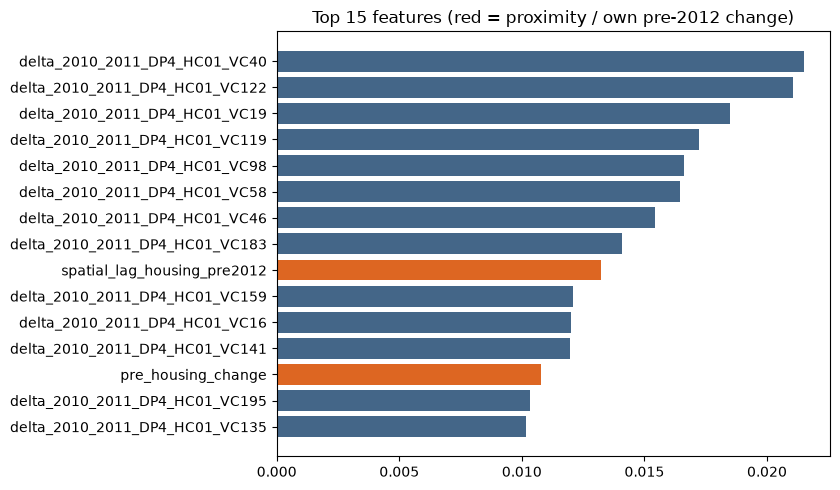

In [14]:
imp_model = fitted_models["xgb"]
imp = pd.Series(imp_model.named_steps["m"].feature_importances_, index=cols_best).sort_values(ascending=False)
top = imp.head(15)[::-1]
colors = ["#d62" if (c in prox_like or c in PRE_F) else "#468" for c in top.index]
plt.figure(figsize=(8.5, 5)); plt.barh(top.index, top.values, color=colors)
plt.title("Top 15 features (red = proximity / own pre-2012 change)"); plt.tight_layout()
plt.show()

## 13. Live demo: score individual tracts

In [15]:
def score_tract(tract_id):
    """Look up one test-set tract and show the selected model's prediction next to the truth."""
    r = pred_df[pred_df.tract_id == tract_id]
    if r.empty:
        return "tract_id not in the test set"
    r = r.iloc[0]
    pct = (pred_df[f"score_{BEST_MODEL}"] <= r[f"score_{BEST_MODEL}"]).mean()
    return (f"Tract {int(tract_id)} | model score percentile: {pct:.0%} | predicted: "
            f"{'RISE' if r.predicted_label_selected else 'no rise'} | actual: {'RISE' if r.actual_label else 'no rise'} "
            f"| actual cost change: ${r.actual_cost_change:,.0f}/month")

demo = pred_df.sample(8, random_state=1)
for t_id in demo.tract_id: print(score_tract(t_id))

Tract 6071009118 | model score percentile: 3% | predicted: no rise | actual: no rise | actual cost change: $-113/month
Tract 6037189202 | model score percentile: 66% | predicted: RISE | actual: RISE | actual cost change: $23/month
Tract 6037201302 | model score percentile: 69% | predicted: RISE | actual: RISE | actual cost change: $37/month
Tract 6095251804 | model score percentile: 9% | predicted: no rise | actual: no rise | actual cost change: $-188/month
Tract 6013303204 | model score percentile: 32% | predicted: no rise | actual: RISE | actual cost change: $147/month
Tract 6093000600 | model score percentile: 42% | predicted: no rise | actual: RISE | actual cost change: $53/month
Tract 6019005607 | model score percentile: 65% | predicted: RISE | actual: RISE | actual cost change: $2/month
Tract 6073013104 | model score percentile: 91% | predicted: RISE | actual: RISE | actual cost change: $24/month


## 14. Results summary (auto-generated from this run)

In [16]:
cv_row = tune_table[(tune_table.drop_below == BEST_THR) & (tune_table.key == BEST_MODEL)].iloc[0]
verdict = ("The 95% CI of the test AUC excludes 0.5, so the model carries a statistically detectable signal."
           if auc_ci[0] > 0.5 else
           "The 95% CI of the test AUC includes 0.5, so on this test set the model cannot be distinguished from chance.")
prox_txt = (f"removing the proximity / neighbour-contrast features changes CV AUC by {abl_mean:+.4f} (SE {abl_se:.4f}); "
            + ("a small but consistent contribution" if abl_sig else "not clearly different from zero")
            + " (folds overlap, so treat this as indicative).")
summary_md = f"""
| Item | Value |
|---|---|
| Rows (development / test) | {len(y_dev)} / {len(y_te)} |
| Features in final model | {len(cols_best)} (`{best_fs}`) |
| Selected algorithm | **{ALGO[BEST_MODEL]}** (training filter: abs(change) >= {BEST_THR}) |
| CV ROC-AUC (train+val) | {cv_row.AUC:.4f} ± {cv_row.AUC_sd:.4f} |
| **Test ROC-AUC** | **{auc_te:.4f}** (95% CI {auc_ci[0]:.3f}–{auc_ci[1]:.3f}) |
| **Test accuracy** | **{acc_te:.4f}** (95% CI {acc_ci[0]:.3f}–{acc_ci[1]:.3f}); majority baseline {base_acc:.4f} |

{verdict}

Proximity ablation ({ALGO[BEST_MODEL]}): {prox_txt}
"""
display(Markdown(summary_md))


| Item | Value |
|---|---|
| Rows (development / test) | 7566 / 399 |
| Features in final model | 160 (`C  + neighbour contrasts`) |
| Selected algorithm | **XGBoost Regressor** (training filter: abs(change) >= 0) |
| CV ROC-AUC (train+val) | 0.7056 ± 0.0123 |
| **Test ROC-AUC** | **0.7082** (95% CI 0.661–0.754) |
| **Test accuracy** | **0.6391** (95% CI 0.594–0.692); majority baseline 0.5188 |

The 95% CI of the test AUC excludes 0.5, so the model carries a statistically detectable signal.

Proximity ablation (XGBoost Regressor): removing the proximity / neighbour-contrast features changes CV AUC by +0.0031 (SE 0.0013); a small but consistent contribution (folds overlap, so treat this as indicative).


## 15. Limitations and conclusions
- **Label noise.** The target is the sign of a noisy median-cost change; tracts with small changes are close to unpredictable (section 10). This caps accuracy for any model.
- **Association, not causation.** Proximity features are predictive indicators, not proof that neighbours cause gentrification.
- **Single time window and region.** One pivot year (2012) in one state; temporal or out-of-region validity is untested.
- **Selection optimism.** Feature-set choice and tuning use CV on the same development data, so CV scores are slightly optimistic; the test result (section 11) is the honest estimate, and its confidence interval shows what a ~400-tract test set can resolve.
- **Model differences.** The tree-based models are typically within noise of each other; the clear gaps are tree-based vs. the linear baseline and census-delta feature sets vs. the core set.
- **Data provenance.** The dataset was assembled with AI assistance from Census ACS files; its alignment was verified against the raw Census data and the delta columns were rebuilt (section 2).
- **Future work.** Distance-weighted neighbourhoods, pre-period *levels* (not only changes), and spatial / temporal hold-out validation.

The conclusions that apply to *this* run are in the auto-generated summary (section 14); quote only those numbers in the report and slides.